In [1]:
import keras
from keras import layers 

In [ ]:
inputs = keras.Input(shape = (28,28,1)) # ConvNet takes an input tensors of shape (image_height, image_width, image_channels)
""" 
- filters = how many different feature detectors this layer learns (64). Each filter scans the imge looking for one pattern (edge, texture, color blob). More filters mean more patterns learned and the output has many channels. 
- kernel_size = the siz eof the sliding window each filter looks through, in pixels (e.g 3 means a 3x3 window). 
- Activation -> nonlinearity applied after the convolution math ("relu" means zeroes out negative values) 
"""
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

In [3]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 372,234 (1.42 MB)

 Trainable params: 372,234 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from keras.datasets import mnist 
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype("float32") / 255 # Normalization 
test_images = test_images.reshape((10000, 28, 28, 1))
test_images =test_images.astype("float32") / 255 
model.compile(
    optimizer= "adam", 
    loss = "sparse_categorical_crossentropy", 
    metrics= ["accuracy"]
)

In [7]:
model.fit(train_images, train_labels, epochs = 5, batch_size= 64)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9212 - loss: 0.2534
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.9792 - loss: 0.0681
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9857 - loss: 0.0461
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9891 - loss: 0.0351
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9912 - loss: 0.0269


In [8]:
# Evalulate the model on the test data 
test_loss ,test_acc = model.evaluate(test_images, test_labels)
print(f"Test Accuracy: {test_acc:.3f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9892 - loss: 0.0340
Test Accuracy: 0.989


In [ ]:
# Convolution operation

# - Dense layers learn global patterns in their input feature space, whereas convolution layers learn local patterns in the case of images, patters found in small 2D windows of the inputs. 

# ConvNets properties: 
#   translation invariant: after learning a certain patterns in the lower right corner of a picture, a ConvNet can recognize it anywhere: for example in the uppter left corner. The visual world is fundamentally translation invariant. 
# they can learn spatial hierarchies of patterns: first layer learn small local patterns, second layer will learn larger patterns made of the features of the first layers. 



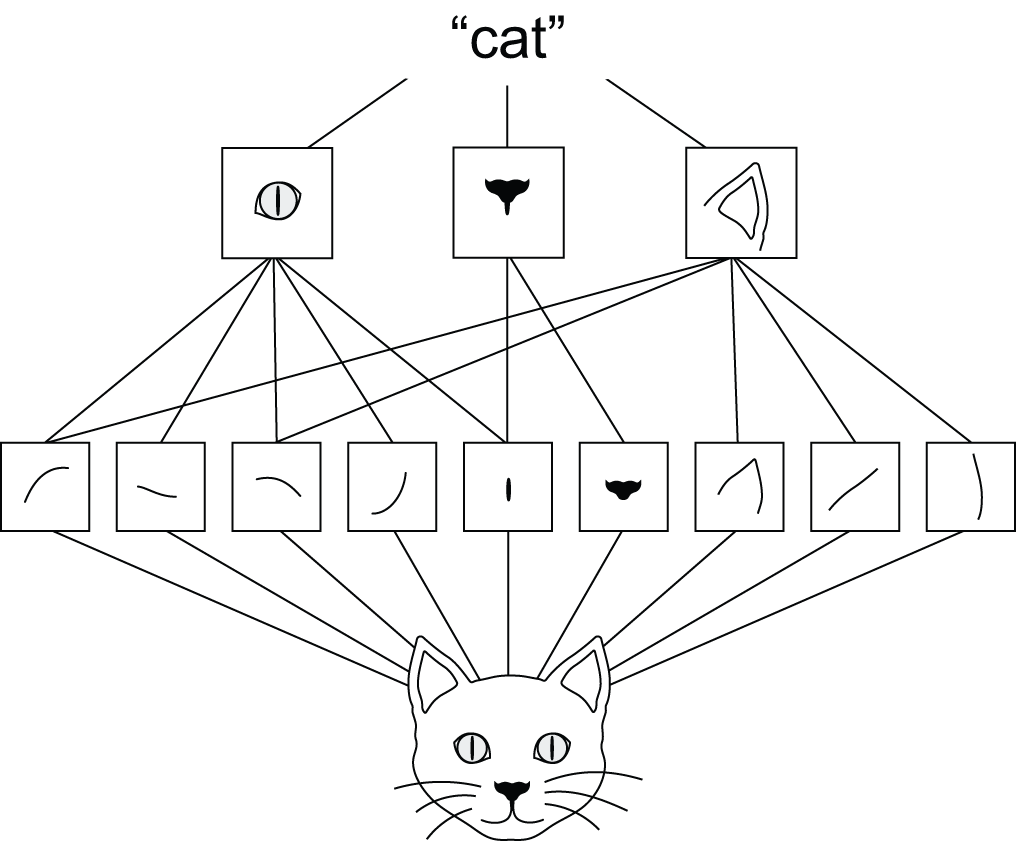

In [ ]:
# Convolutions operate over rank 3 tensors, feature maps.
# Spatial axes height and widt and a depth axis called channels axis. For RGB image, the dimensions of the depth axis is 3, because the image has three color channels.  